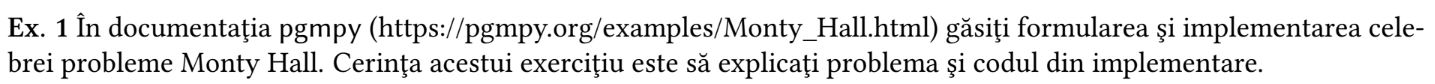

In [1]:
#fie C = i, H = j, i,j din {0,1,2}
#trebuie sa aflam P(P | H = j, C = i) pentru fiecare P
# P(P | H, C) = P(P,H,C) / P(H,C)
# P(P,H,C) = P(P) P(C) P(H|P,C)
#cunoastem P(H|P,C) deci putem afla P(P,H,C) pentru orice P
#P(H,C) o aflam folosind probablitatea totala
#=> aflam P(P | H = j, C = i) pentru fiecare P


In [ ]:
#DiscreteBayesianNetwork([("C", "H"), ("P", "H")]) --initializeaza dependentele

#TabularCPD initializeaza prob indep si dependente

#VariableElimination(model) si infer.query(["P"], evidence={"C": 0, "H": 2}) executa calculele de mai sus

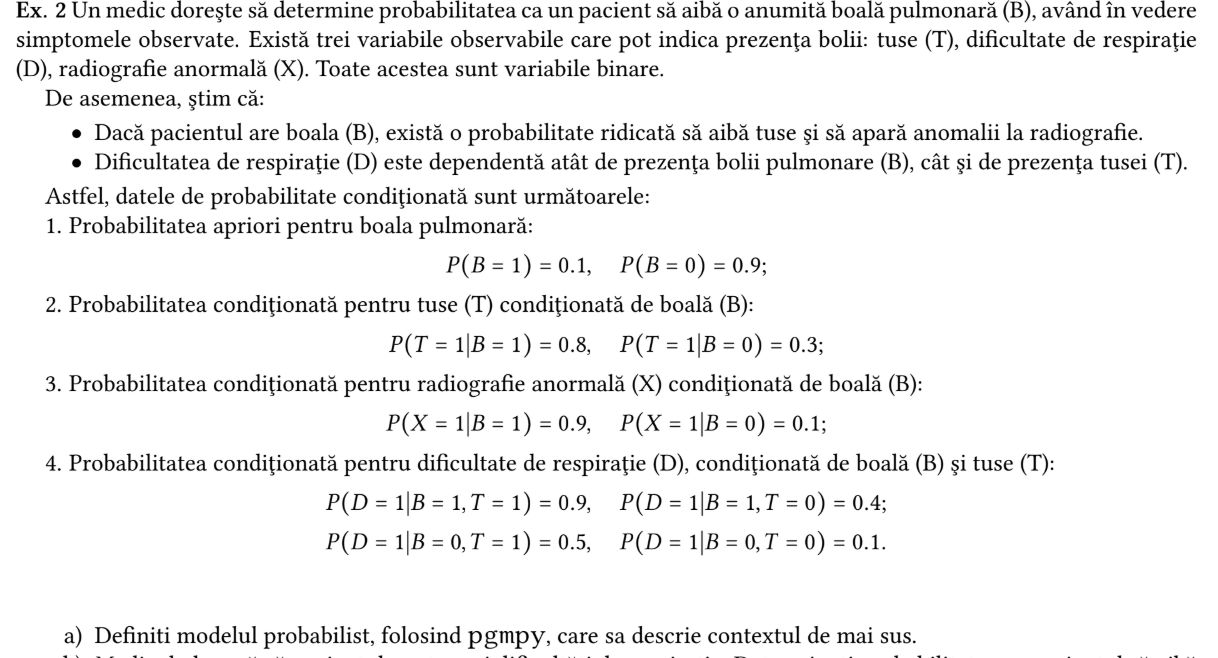

In [4]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

model = DiscreteBayesianNetwork([
    ('B', 'T'), 
    ('B', 'X'), 
    ('B', 'D'), 
    ('T', 'D')
])

cpd_b = TabularCPD(variable='B', variable_card=2, values=[[0.9], [0.1]])

cpd_t = TabularCPD(variable='T', variable_card=2, values=[[0.7, 0.2], [0.3, 0.8]], 
                   evidence=['B'], evidence_card=[2])

cpd_x = TabularCPD(variable='X', variable_card=2, values=[[0.9, 0.1], [0.1, 0.9]], 
                   evidence=['B'], evidence_card=[2])

cpd_d = TabularCPD(variable='D', variable_card=2, 
                   values=[[0.9, 0.5, 0.6, 0.1],   #D = 0
                           [0.1, 0.5, 0.4, 0.9]],  #D = 1
                   evidence=['B', 'T'], 
                   evidence_card=[2, 2])

model.add_cpds(cpd_b, cpd_t, cpd_x, cpd_d)

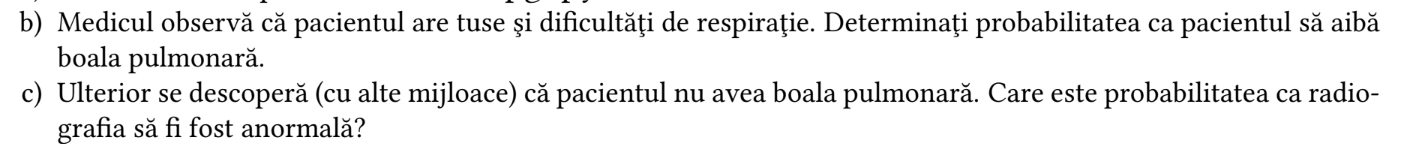


In [5]:
from pgmpy.inference import VariableElimination

infer = VariableElimination(model)

#b) P(B | T=1, D=1)
res_b = infer.query(variables=['B'], evidence={'T': 1, 'D': 1})
print(res_b)

#c) P(X | B=0, T=1, D=1) 
res_c = infer.query(variables=['X'], evidence={'B': 0, 'T': 1, 'D': 1})
print(res_c)

D:\facultate\PMP\PMP-2026\.venv\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6522 |
+------+----------+
| B(1) |   0.3478 |
+------+----------+
+------+----------+
| X    |   phi(X) |
+======+==========+
| X(0) |   0.9000 |
+------+----------+
| X(1) |   0.1000 |
+------+----------+


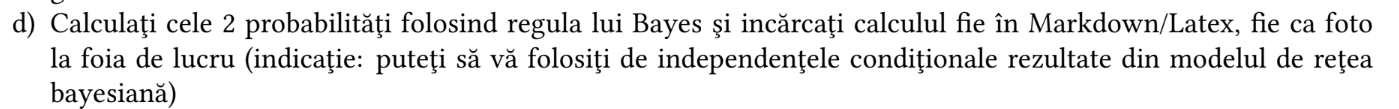

In [ ]:
#P(B=1|T=1,D=1) = P(B=1,T=1,D=1) / P(T=1,D=1)
#P(B,T,D) = P(B) P(T|B) P(D|T,B)
#P(B=1,T=1,D=1) = 0.072

#P(T=1,D=1) = P(B=1,T,D) + P(B=0,T,D)
#P(B=0,T=1,D=1) = P(B=0) P(T=1 | B = 0) P(D=1 | B=0,T=1)
#P(B=0,T=1,D=1) = 0.135
#P(T=1,D=1) = 0.207

#P(B=1|T=1,D=1) = 0.34

#P(X=1 |B=0) = 0.1

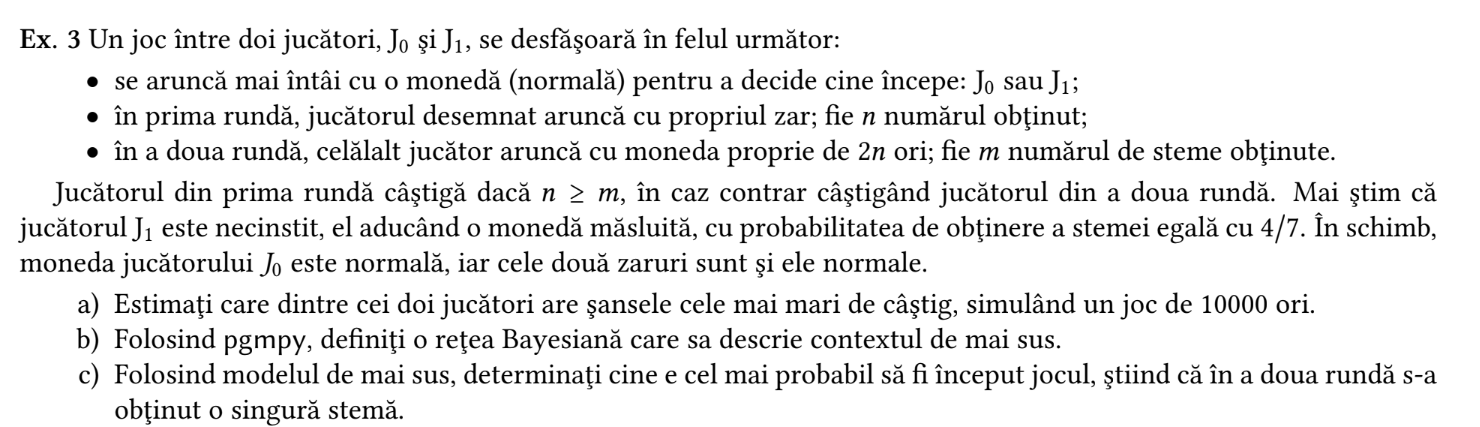

In [8]:
import random

victorii_J0 = 0
victorii_J1 = 0

for _ in range(10000):
    if random.random() < 0.5:
        start = 0
    else:
        start = 1

    n = random.choice([1, 2, 3, 4, 5, 6])
    m = 0
    
    for _ in range(2 * n):
            if start == 0:
                if random.random() < 4/7:
                    m += 1
            else:
                if random.random() < 0.5:
                    m += 1

    if n >= m:
        if start == 0:
            victorii_J0 += 1
        else:
            victorii_J1 += 1
    else:
        if start == 0:
            victorii_J1 += 1
        else:
            victorii_J0 += 1

print(f"J0: {victorii_J0}")
print(f"J1: {victorii_J1}")

J0: 4207
J1: 5793


In [1]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from scipy.stats import binom

model = DiscreteBayesianNetwork([('S', 'M'), ('N', 'M')])

cpd_s = TabularCPD(variable='S', variable_card=2, values=[[0.5], [0.5]])
cpd_n = TabularCPD(variable='N', variable_card=6, values=[[1/6], [1/6], [1/6], [1/6], [1/6], [1/6]])

m_values = []
for m in range(13):
    row = []
    for s in [0, 1]:
        for n_idx in range(6):
            n = n_idx + 1
            num_aruncari = 2 * n

            p = 4/7 if s == 0 else 0.5

            if m > num_aruncari:
                prob = 0.0
            else:
                prob = binom.pmf(m, num_aruncari, p)
            row.append(prob)
    m_values.append(row)

cpd_m = TabularCPD(variable='M', variable_card=13, 
                   values=m_values, 
                   evidence=['S', 'N'], 
                   evidence_card=[2, 6])

model.add_cpds(cpd_s, cpd_n, cpd_m)
assert model.check_model()

infer = VariableElimination(model)
rezultat = infer.query(variables=['S'], evidence={'M': 1})
print(rezultat)

D:\facultate\PMP\PMP-2026\.venv\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.4529 |
+------+----------+
| S(1) |   0.5471 |
+------+----------+
